

# Corporate Employee Attrition Risk & Tenure Duration Regression Model

**Dataset:** Corporate Employee HR Dataset  
**Records:** 20,000 employees  
**Main ML Tasks:**
- **Regression:** Predict `Years_at_Company`
- **Classification:** Predict `Attrition` (`Yes` / `No`)

This notebook follows the complete 15-step data-analysis workflow required for the project.


# CHAPTER 1: PROJECT DEFINITION

## 1.1 Introduction

Employee attrition is an important HR analytics problem because organizations need to understand which work-related factors are associated with employees leaving the company.

This project performs exploratory data analysis and develops two predictive models:

1. **Tenure Duration Regression Model** — predicts how many years an employee has stayed at the company.
2. **Employee Attrition Risk Classification Model** — predicts whether an employee belongs to the attrition class (`Yes`) or non-attrition class (`No`).




## 1.2 Problem Statement

The project aims to analyze corporate employee characteristics such as age, department, job role, salary, overtime, satisfaction, work-life balance, promotion history, working hours, commute distance, experience, and absenteeism.

The two prediction problems are:

- **Regression target:** `Years_at_Company`
- **Classification target:** `Attrition`

The goal is to build models that generalize well on unseen test data while avoiding target leakage.


## 1.3 Objectives

- Import and understand the employee dataset.
- Clean missing values, duplicate records, and selected outliers.
- Perform univariate, bivariate, and multivariate EDA.
- Study factors associated with employee attrition.
- Build a regression model for employee tenure duration.
- Evaluate regression using MAE, MSE, RMSE, and R².
- Build a classification model for employee attrition.
- Evaluate classification using Accuracy, Precision, Recall, F1 Score, Confusion Matrix, and ROC-AUC.
- Compare training and testing performance to identify underfitting or overfitting.
- Summarize the main analytical findings.


# CHAPTER 2: DATASET DETAILS

## 2.1 Dataset Information

The project uses a ** HR dataset with 20,000 employee records and 30 columns**.

 Amounts of missing data and realistic extreme values were intentionally included so that data-cleaning and outlier-handling steps can be demonstrated.




## 2.2 Main Column Groups

| Group | Example Columns |
|---|---|
| Employee profile | Age, Gender, Marital_Status, Education_Level |
| Job information | Department, Job_Role, Job_Level |
| Compensation | Monthly_Income |
| Workload | Overtime, Average_Weekly_Hours, Business_Travel |
| Work environment | Remote_Work, Environment_Satisfaction |
| Engagement | Job_Satisfaction, Job_Involvement, Relationship_with_Manager |
| Performance | Performance_Rating, Training_Hours_Last_Year |
| Attendance/commute | Distance_From_Home_KM, Absenteeism_Days |
| Career history | Num_Companies_Worked, Total_Working_Years |
| Tenure | Years_at_Company, Years_in_Current_Role, Years_Since_Last_Promotion |
| Promotion | Promotion_Last_3_Years |
| Classification target | Attrition |


# CHAPTER 3: PYTHON TOOLS AND LIBRARIES USED

The analysis uses:

- **Pandas** — data loading and manipulation
- **NumPy** — numerical operations
- **Matplotlib** — charts and visualization
- **Scikit-learn** — preprocessing, regression, classification, train/test split, and evaluation


# CHAPTER 4: IMPORTING, LOADING & UNDERSTANDING THE DATA

## Step 1: Importing Necessary Python Libraries


In [1]:
import os
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
#!mamba install pandas numpy matplotlib seaborn scikit-learn
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully.")

Libraries imported successfully.


## Step 2: Loading Data & Creating the DataFrame

Place `corporate_employee_attrition_tenure_20000.csv` in the same directory as this notebook.

The code also checks `/mnt/data/` so this prepared notebook can run in the current environment.


In [2]:
# Step 2: Loading dataset and creating DataFrame
candidate_paths = [
    Path("corporate_employee_attrition_tenure_20000.csv"),
    Path("/mnt/data/corporate_employee_attrition_tenure_20000.csv")
]

DATA_PATH = None
for path in candidate_paths:
    if path.exists():
        DATA_PATH = path
        break

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Put 'corporate_employee_attrition_tenure_20000.csv' "
        "in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset loaded from:", DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())


Dataset loaded from: corporate_employee_attrition_tenure_20000.csv
Dataset shape: (20000, 30)


,Employee_ID,Age,Gender,Marital_Status,Education_Level,Department,Job_Role,Job_Level,Monthly_Income,Overtime,Average_Weekly_Hours,Business_Travel,Remote_Work,Job_Satisfaction,Environment_Satisfaction,Work_Life_Balance,Job_Involvement,Relationship_with_Manager,Performance_Rating,Training_Hours_Last_Year,Distance_From_Home_KM,Absenteeism_Days,Num_Companies_Worked,Total_Working_Years,Years_at_Company,Years_in_Current_Role,Years_Since_Last_Promotion,Years_with_Current_Manager,Promotion_Last_3_Years,Attrition
0,EMP100001,39,Male,Married,High School,HR,Recruiter,3,95300.0,No,33.7,NaN,Hybrid,2.0,2.0,3,2,3.0,3,36.0,20.0,11,2,17,10,7,7,5,No,No
1,EMP100002,27,Female,Married,Master,Finance,Financial Analyst,2,78500.0,Yes,54.3,Occasional,Full Remote,5.0,1.0,4,3,4.0,3,37.0,3.0,2,1,7,4,4,1,2,Yes,No
2,EMP100003,42,Male,Single,Diploma,Operations,Operations Manager,3,88800.0,Yes,47.5,Frequent,No,2.0,1.0,3,3,3.0,4,40.0,7.0,4,6,16,4,3,2,2,No,Yes
3,EMP100004,44,Female,Single,Master,IT,QA Engineer,4,153200.0,No,28.0,Occasional,Hybrid,4.0,2.0,4,2,4.0,2,38.0,24.0,4,3,22,15,10,6,7,No,No
4,EMP100005,21,Female,Married,Bachelor,IT,QA Engineer,1,51500.0,Yes,47.1,Occasional,Hybrid,4.0,4.0,2,2,1.0,3,22.0,15.0,4,0,0,0,0,0,0,No,Yes


## Step 3: Understanding the Data

We inspect:

- Shape
- Column names
- Data types
- Basic statistical summary
- Number of unique values
- Class distribution of `Attrition`


In [3]:
# Step 3: Basic dataset information
print("Shape of dataset:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nDataFrame Information:")
df.info()


Shape of dataset: (20000, 30)

Columns:
['Employee_ID', 'Age', 'Gender', 'Marital_Status', 'Education_Level', 'Department', 'Job_Role', 'Job_Level', 'Monthly_Income', 'Overtime', 'Average_Weekly_Hours', 'Business_Travel', 'Remote_Work', 'Job_Satisfaction', 'Environment_Satisfaction', 'Work_Life_Balance', 'Job_Involvement', 'Relationship_with_Manager', 'Performance_Rating', 'Training_Hours_Last_Year', 'Distance_From_Home_KM', 'Absenteeism_Days', 'Num_Companies_Worked', 'Total_Working_Years', 'Years_at_Company', 'Years_in_Current_Role', 'Years_Since_Last_Promotion', 'Years_with_Current_Manager', 'Promotion_Last_3_Years', 'Attrition']

DataFrame Information:
<class 'pandas.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 30 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Employee_ID                 20000 non-null  str    
 1   Age                         20000 non-null  int64  
 2   Gende

In [4]:
# Numerical summary
display(df.describe().T)


,count,mean,std,min,25%,50%,75%,max
Age,20000.0,36.170200,8.243229,21.0,30.0,36.0,42.0,60.0
Job_Level,20000.0,2.697750,1.157308,1.0,2.0,3.0,4.0,5.0
Monthly_Income,19760.0,95534.716599,36041.244603,18000.0,68100.0,93100.0,120300.0,216800.0
Average_Weekly_Hours,20000.0,43.632755,9.979337,28.0,36.0,43.0,50.6,75.0
Job_Satisfaction,19700.0,3.104975,1.207598,1.0,2.0,3.0,4.0,5.0
Environment_Satisfaction,19760.0,3.079960,1.164788,1.0,2.0,3.0,4.0,5.0
Work_Life_Balance,20000.0,3.224600,1.122817,1.0,2.0,3.0,4.0,5.0
Job_Involvement,20000.0,2.997550,0.897711,1.0,2.0,3.0,4.0,5.0
Relationship_with_Manager,19700.0,3.096091,1.140941,1.0,2.0,3.0,4.0,5.0
Performance_Rating,20000.0,3.252450,0.738814,1.0,3.0,3.0,4.0,5.0


In [5]:
# Categorical summary
display(df.describe(include="object").T)


,count,unique,top,freq
Employee_ID,20000,20000,EMP100001,1
Gender,20000,2,Male,11197
Marital_Status,20000,3,Married,10404
Education_Level,19840,5,Bachelor,9664
Department,19880,8,IT,3997
Job_Role,20000,25,Account Manager,1122
Overtime,20000,2,No,12831
Business_Travel,14480,2,Occasional,11327
Remote_Work,20000,3,No,9305
Promotion_Last_3_Years,20000,2,No,13428


In [6]:
# Unique values per column
unique_summary = pd.DataFrame({
    "Column": df.columns,
    "Unique_Values": [df[col].nunique(dropna=True) for col in df.columns]
})
display(unique_summary)


,Column,Unique_Values
0,Employee_ID,20000
1,Age,40
2,Gender,2
3,Marital_Status,3
4,Education_Level,5
5,Department,8
6,Job_Role,25
7,Job_Level,5
8,Monthly_Income,1713
9,Overtime,2


# CHAPTER 5: UNDERSTANDING SPREAD OF DATA

## Step 4: Data Cleaning and Preparation — Understanding Spread

Before modelling, we examine:

- Duplicate rows
- Numerical distributions
- Mean, median, standard deviation, skewness, and kurtosis


In [7]:
# Duplicate check
duplicate_count = df.duplicated().sum()
print("Duplicate rows:", duplicate_count)


Duplicate rows: 0


In [8]:
# Statistical spread for selected continuous variables
spread_features = [
    "Age",
    "Monthly_Income",
    "Average_Weekly_Hours",
    "Distance_From_Home_KM",
    "Absenteeism_Days",
    "Total_Working_Years",
    "Years_at_Company"
]

spread_table = pd.DataFrame({
    "Mean": df[spread_features].mean(),
    "Median": df[spread_features].median(),
    "Std_Dev": df[spread_features].std(),
    "Skewness": df[spread_features].skew(),
    "Kurtosis": df[spread_features].kurt()
}).round(3)

display(spread_table)


,Mean,Median,Std_Dev,Skewness,Kurtosis
Age,36.170,36.0,8.243,0.182,-0.384
Monthly_Income,95534.717,93100.0,36041.245,0.326,-0.442
Average_Weekly_Hours,43.633,43.0,9.979,0.335,-0.512
Distance_From_Home_KM,11.005,9.0,7.402,1.303,2.296
Absenteeism_Days,6.106,5.0,3.470,1.282,2.624
Total_Working_Years,13.489,13.0,8.442,0.302,-0.464
Years_at_Company,7.584,7.0,5.334,0.503,-0.336


In [49]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


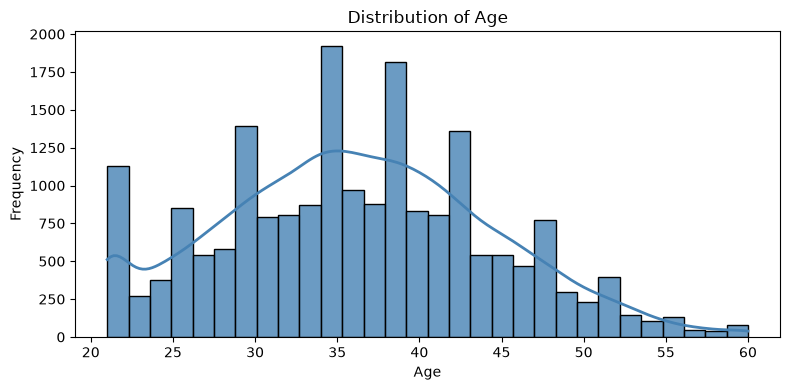

Interpretation of Age:
The Age values range from 21.00 to 60.00, with a mean of 36.17 and a median of 36.00.
The distribution is approximately symmetric, indicating that the values are fairly balanced around the centre.
The histogram and KDE curve help identify the overall spread, shape, and concentration of employees across different Age values.
----------------------------------------------------------------------------------------------------


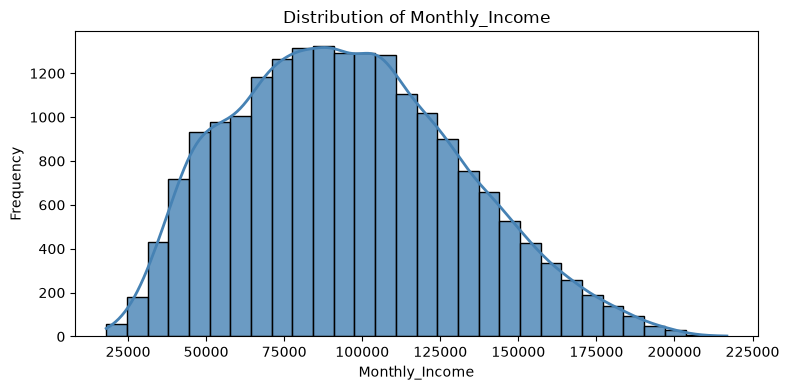

Interpretation of Monthly_Income:
The Monthly_Income values range from 18000.00 to 216800.00, with a mean of 95534.72 and a median of 93100.00.
The distribution is approximately symmetric, indicating that the values are fairly balanced around the centre.
The histogram and KDE curve help identify the overall spread, shape, and concentration of employees across different Monthly_Income values.
----------------------------------------------------------------------------------------------------


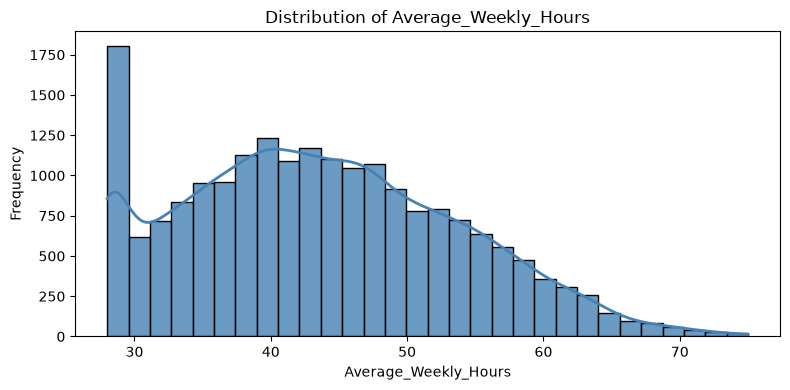

Interpretation of Average_Weekly_Hours:
The Average_Weekly_Hours values range from 28.00 to 75.00, with a mean of 43.63 and a median of 43.00.
The distribution is approximately symmetric, indicating that the values are fairly balanced around the centre.
The histogram and KDE curve help identify the overall spread, shape, and concentration of employees across different Average_Weekly_Hours values.
----------------------------------------------------------------------------------------------------


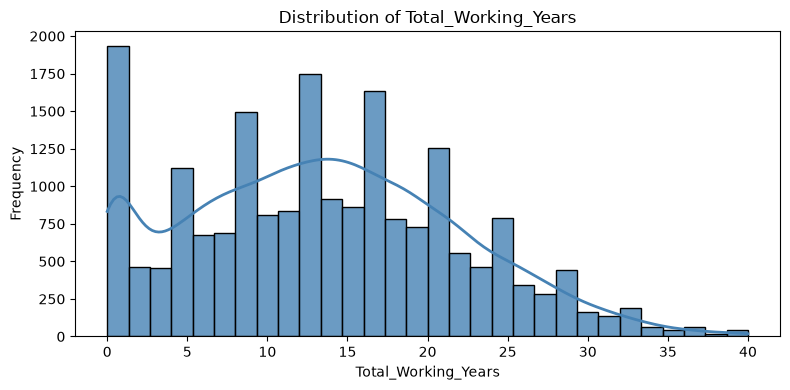

Interpretation of Total_Working_Years:
The Total_Working_Years values range from 0.00 to 40.00, with a mean of 13.49 and a median of 13.00.
The distribution is approximately symmetric, indicating that the values are fairly balanced around the centre.
The histogram and KDE curve help identify the overall spread, shape, and concentration of employees across different Total_Working_Years values.
----------------------------------------------------------------------------------------------------


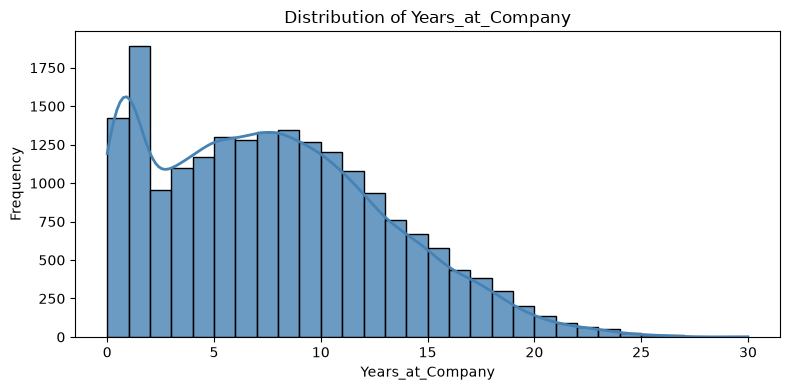

Interpretation of Years_at_Company:
The Years_at_Company values range from 0.00 to 30.00, with a mean of 7.58 and a median of 7.00.
The distribution is positively skewed (right-skewed), indicating that most observations are concentrated toward lower values, with some higher values extending the distribution.
The histogram and KDE curve help identify the overall spread, shape, and concentration of employees across different Years_at_Company values.
----------------------------------------------------------------------------------------------------


In [50]:

import seaborn as sns
import matplotlib.pyplot as plt

# Distribution plots with KDE and automatic professional interpretation
for col in [
    "Age",
    "Monthly_Income",
    "Average_Weekly_Hours",
    "Total_Working_Years",
    "Years_at_Company"
]:
    data = df[col].dropna()

    # Histogram with KDE curve
    plt.figure(figsize=(8, 4))

    sns.histplot(
        data=data,
        bins=30,
        kde=True,
        edgecolor="black",
        alpha=0.8,
        color="steelblue",
        line_kws={"color": "red", "linewidth": 2}
    )

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

    # Calculate statistics for interpretation
    min_val = data.min()
    max_val = data.max()
    median_val = data.median()
    mean_val = data.mean()
    skewness = data.skew()

    # Automatic interpretation
    print(f"Interpretation of {col}:")
    print(
        f"The {col} values range from {min_val:.2f} to {max_val:.2f}, "
        f"with a mean of {mean_val:.2f} and a median of {median_val:.2f}."
    )

    if abs(skewness) < 0.5:
        print(
            "The distribution is approximately symmetric, indicating that "
            "the values are fairly balanced around the centre."
        )
    elif skewness >= 0.5:
        print(
            "The distribution is positively skewed (right-skewed), indicating "
            "that most observations are concentrated toward lower values, "
            "with some higher values extending the distribution."
        )
    else:
        print(
            "The distribution is negatively skewed (left-skewed), indicating "
            "that most observations are concentrated toward higher values, "
            "with some lower values extending the distribution."
        )

    print(
        f"The histogram and KDE curve help identify the overall spread, "
        f"shape, and concentration of employees across different {col} values."
    )
    print("-" * 100)


# CHAPTER 6: MISSING DATA AND OUTLIERS

## Step 5: Checking for Missing Data and Outliers

Missing values are counted by column.

For numerical features, potential outliers are identified using the **IQR method**:

- Lower bound = Q1 − 1.5 × IQR
- Upper bound = Q3 + 1.5 × IQR


In [10]:
# Missing-value summary
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().sum() / len(df) * 100).round(2)
})

missing_summary = missing_summary[missing_summary["Missing_Count"] > 0]
display(missing_summary)


,Missing_Count,Missing_Percentage
Education_Level,160,0.8
Department,120,0.6
Monthly_Income,240,1.2
Business_Travel,5520,27.6
Job_Satisfaction,300,1.5
Environment_Satisfaction,240,1.2
Relationship_with_Manager,300,1.5
Training_Hours_Last_Year,360,1.8
Distance_From_Home_KM,200,1.0


In [11]:
# IQR-based outlier counts for numerical columns
def outlier_summary(dataframe):
    result = []
    for col in dataframe.select_dtypes(include=np.number).columns:
        series = dataframe[col].dropna()
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - 1.5 * IQR
        upper = Q3 + 1.5 * IQR
        count = ((series < lower) | (series > upper)).sum()
        result.append([col, count, lower, upper])
    return pd.DataFrame(
        result,
        columns=["Column", "Outlier_Count", "Lower_Bound", "Upper_Bound"]
    ).sort_values("Outlier_Count", ascending=False)

outlier_table_before = outlier_summary(df)
display(outlier_table_before)


,Column,Outlier_Count,Lower_Bound,Upper_Bound
17,Years_Since_Last_Promotion,1069,-3.5,8.5
13,Num_Companies_Worked,803,-2.0,6.0
11,Distance_From_Home_KM,586,-7.5,28.5
12,Absenteeism_Days,526,-2.0,14.0
16,Years_in_Current_Role,353,-4.0,12.0
18,Years_with_Current_Manager,301,-5.0,11.0
9,Performance_Rating,115,1.5,5.5
10,Training_Hours_Last_Year,98,3.0,75.0
14,Total_Working_Years,58,-11.0,37.0
15,Years_at_Company,55,-9.0,23.0


## Step 6: Handling Missing Data and Selected Outliers

For this academic workflow:

- Duplicate records are removed.
- Missing numerical values are filled with the **mean**.
- Missing categorical values are filled with the **mode**.
- Selected continuous-variable outliers are capped using IQR bounds.

We do **not** cap every numerical variable. For example, legitimate values such as long work experience or long tenure should not automatically be treated as errors.


In [12]:
# Create a clean copy
df_clean = df.copy()

# Remove duplicates
df_clean.drop_duplicates(inplace=True)

# Fill missing numerical values with mean
numeric_columns = df_clean.select_dtypes(include=np.number).columns
for col in numeric_columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mean())

# Fill missing categorical values with mode
categorical_columns = df_clean.select_dtypes(include="object").columns
for col in categorical_columns:
    if df_clean[col].isnull().any():
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

print("Remaining missing values:", df_clean.isnull().sum().sum())
print("Shape after duplicate removal:", df_clean.shape)


Remaining missing values: 0
Shape after duplicate removal: (20000, 30)


In [13]:
# Cap selected continuous-feature outliers using IQR
outlier_cap_columns = [
    "Monthly_Income",
    "Average_Weekly_Hours",
    "Distance_From_Home_KM",
    "Absenteeism_Days",
    "Training_Hours_Last_Year"
]

capping_report = []

for col in outlier_cap_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    before = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    df_clean[col] = df_clean[col].clip(lower, upper)
    after = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()

    capping_report.append([col, before, after, round(lower, 2), round(upper, 2)])

capping_report = pd.DataFrame(
    capping_report,
    columns=["Column", "Before_Capping", "After_Capping", "Lower_Bound", "Upper_Bound"]
)

display(capping_report)


,Column,Before_Capping,After_Capping,Lower_Bound,Upper_Bound
0,Monthly_Income,42,0,-8700.0,196900.0
1,Average_Weekly_Hours,37,0,14.1,72.5
2,Distance_From_Home_KM,586,0,-7.5,28.5
3,Absenteeism_Days,526,0,-2.0,14.0
4,Training_Hours_Last_Year,172,0,4.5,72.5


In [14]:
# Final data-quality check
print("Total missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

# Save cleaned dataset
cleaned_file = "cleaned_employee_attrition_tenure.csv"
df_clean.to_csv(cleaned_file, index=False)

print("Clean dataset saved as:", cleaned_file)


Total missing values: 0
Duplicate rows: 0
Clean dataset saved as: cleaned_employee_attrition_tenure.csv


# AUTOMATED EDA REPORT — YDATA PROFILING

## Step 7: Automated Exploratory Data Analysis

YData Profiling is used to automatically generate a detailed exploratory data analysis report from the cleaned employee dataset (`df_clean`).

The report provides an overview of:
- Dataset structure and variable types
- Missing values and duplicate records
- Descriptive statistics
- Distributions of numerical and categorical variables
- Correlations and relationships between variables
- Potential data-quality issues and warnings

The generated report is saved as an HTML file so it can be opened separately in a web browser.

In [15]:
# If YData Profiling is not installed, run this once in a separate cell:
#!mamba install ydata-profiling

from ydata_profiling import ProfileReport

# Create the automated EDA report from the cleaned dataset
YDATA_REPORT_FILE = "ydata_employee_attrition_report.html"

profile = ProfileReport(
    df_clean,
    title="Corporate Employee Attrition - Automated EDA Report",
    minimal=True
)

# Display the report inside the notebook
profile.to_notebook_iframe()

# Save the complete interactive report as an HTML file
profile.to_file(YDATA_REPORT_FILE)

print("YData Profiling report generated successfully!")
print("Report saved as:", YDATA_REPORT_FILE)

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 30/30 [00:00<00:00, 237.43it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

YData Profiling report generated successfully!
Report saved as: ydata_employee_attrition_report.html


# CHAPTER 7: EDA — UNIVARIATE ANALYSIS

## Step 7: Univariate Analysis

This section studies one variable at a time.

Questions explored:

- What is the attrition distribution?
- What is the employee tenure distribution?
- Which departments contain the most employees?
- How common is overtime?
- How are job-satisfaction scores distributed?
- What is the monthly-income distribution?


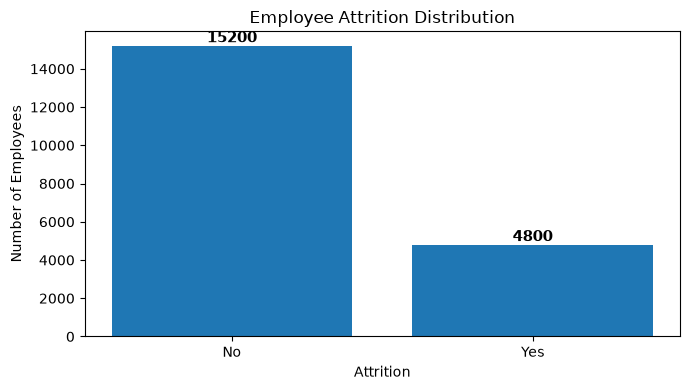

Attrition
No     76.0
Yes    24.0
Name: Percentage, dtype: float64

In [16]:
# 7.1 Attrition distribution

attrition_counts = df_clean["Attrition"].value_counts()

plt.figure(figsize=(7, 4))
bars = plt.bar(attrition_counts.index, attrition_counts.values)

plt.title("Employee Attrition Distribution")
plt.xlabel("Attrition")
plt.ylabel("Number of Employees")

# Show number on each bar
for bar, value in zip(bars, attrition_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

attrition_percentage = (
    df_clean["Attrition"].value_counts(normalize=True) * 100
).round(2)

display(attrition_percentage.rename("Percentage"))

### Interpretation — Employee Attrition Distribution

The chart shows that **15,200 employees (76%) have not left the company**, while **4,800 employees (24%) have left**. Therefore, the dataset contains substantially more employees with **No Attrition** than **Attrition**. This indicates that the target classes are imbalanced, so classification performance should not be judged using accuracy alone; metrics such as precision, recall, F1-score and ROC-AUC are also important.


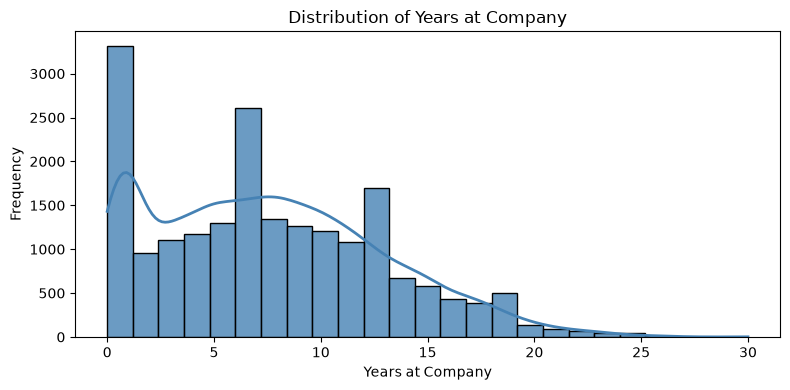

Average tenure: 7.58 years
Median tenure : 7.0 years


In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

# 7.2 Tenure distribution with KDE
plt.figure(figsize=(8, 4))

sns.histplot(
    data=df_clean,
    x="Years_at_Company",
    bins=25,
    kde=True,
    edgecolor="black",
    alpha=0.8,
    color="steelblue",
    line_kws={"color": "red", "linewidth": 2}
)

plt.title("Distribution of Years at Company")
plt.xlabel("Years at Company")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Average tenure:", round(df_clean["Years_at_Company"].mean(), 2), "years")
print("Median tenure :", round(df_clean["Years_at_Company"].median(), 2), "years")


### Interpretation — Distribution of Years at Company

The tenure distribution is concentrated around the lower-to-middle years of employment. The **average tenure is 7.58 years** and the **median is 7 years**. The mean being slightly higher than the median indicates a mild right skew, with some employees having considerably longer tenure. Overall, the chart shows meaningful variation in how long employees have stayed with the company.


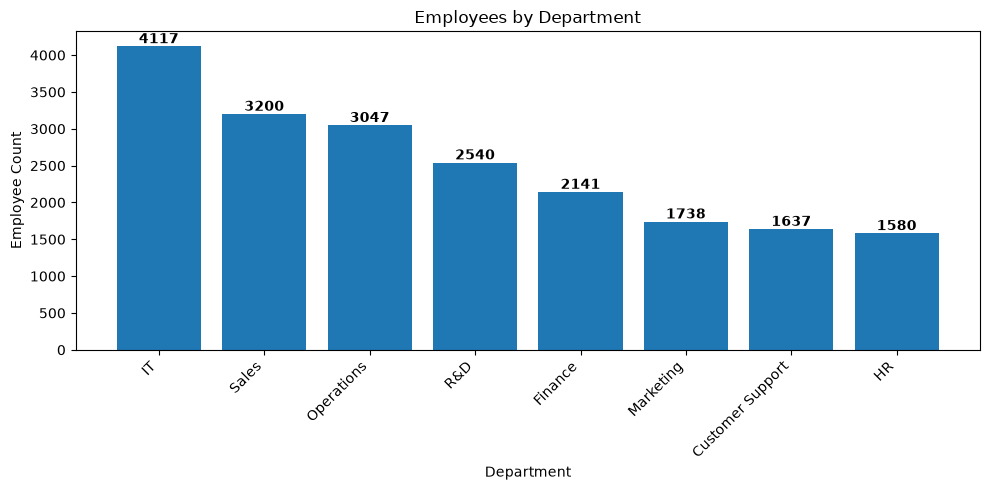

Department
IT                  4117
Sales               3200
Operations          3047
R&D                 2540
Finance             2141
Marketing           1738
Customer Support    1637
HR                  1580
Name: Employee_Count, dtype: int64

In [18]:
# 7.3 Department distribution

department_counts = (
    df_clean["Department"]
    .value_counts()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
bars = plt.bar(
    department_counts.index,
    department_counts.values
)

plt.title("Employees by Department")
plt.xlabel("Department")
plt.ylabel("Employee Count")
plt.xticks(rotation=45, ha="right")

# Show number on each bar
for bar, value in zip(bars, department_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

display(department_counts.rename("Employee_Count"))

### Interpretation — Employees by Department

The chart shows that **IT has the largest number of employees (4,117)**, followed by Sales and Operations. **HR has the smallest number (1,580)** among the departments shown. This means the employee population is not equally distributed across departments, so department-level comparisons should consider the different department sizes.


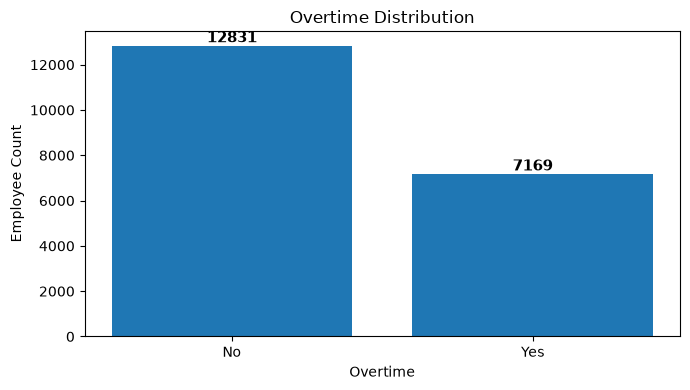

In [19]:
# 7.4 Overtime distribution

overtime_counts = df_clean["Overtime"].value_counts()

plt.figure(figsize=(7, 4))
bars = plt.bar(
    overtime_counts.index,
    overtime_counts.values
)

plt.title("Overtime Distribution")
plt.xlabel("Overtime")
plt.ylabel("Employee Count")

# Show number on each bar
for bar, value in zip(bars, overtime_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value}",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()


### Interpretation — Overtime Distribution

The chart shows that **12,831 employees do not work overtime**, while **7,169 employees do work overtime**. Thus, employees without overtime form the larger group, but a substantial portion of the workforce is still exposed to overtime. This variable becomes particularly important when examining its relationship with attrition in the bivariate analysis.


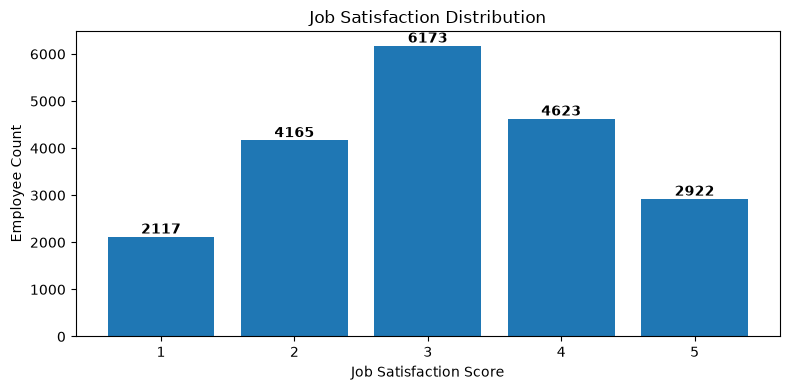

In [20]:
# 7.5 Job satisfaction distribution

satisfaction_display = (
    df_clean["Job_Satisfaction"]
    .round()
    .astype(int)
)

satisfaction_counts = (
    satisfaction_display
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(8, 4))
bars = plt.bar(
    satisfaction_counts.index.astype(str),
    satisfaction_counts.values
)

plt.title("Job Satisfaction Distribution")
plt.xlabel("Job Satisfaction Score")
plt.ylabel("Employee Count")

# Show number on each bar
for bar, value in zip(bars, satisfaction_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()



### Interpretation — Job Satisfaction Distribution

The most common displayed job-satisfaction score is **3**, with **6,173 employees**, followed by score **4** with 4,623 employees. Scores **1** and **5** are less common. This indicates that most employees report moderate to moderately high job satisfaction, while very low satisfaction is present in a smaller group.


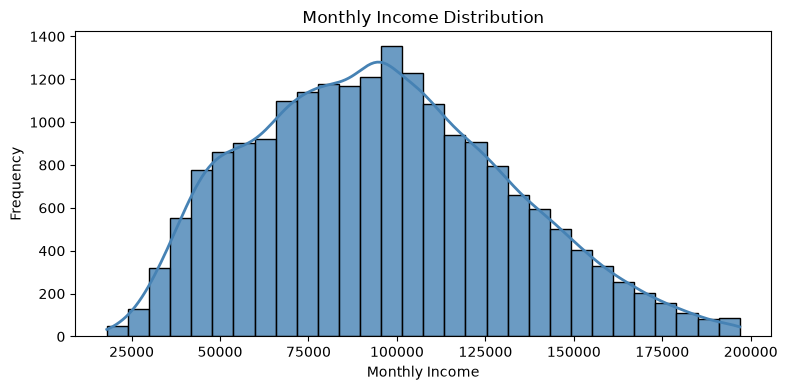

In [56]:

import seaborn as sns
import matplotlib.pyplot as plt

# 7.6 Monthly income distribution with KDE
plt.figure(figsize=(8, 4))

sns.histplot(
    data=df_clean,
    x="Monthly_Income",
    bins=30,
    kde=True,
    edgecolor="black",
    alpha=0.8,
    color="steelblue",
    line_kws={"color": "red", "linewidth": 2}
)

plt.title("Monthly Income Distribution")
plt.xlabel("Monthly Income")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


### Interpretation — Monthly Income Distribution

The chart shows a broad spread of monthly income values, with most employees concentrated around the central income range and fewer employees at the higher end. The mean income (**95,524**) is above the median (**93,900**), which is consistent with a mild right-skewed distribution. This indicates that a smaller number of higher-income employees pull the average upward.


# CHAPTER 8: EDA — BIVARIATE ANALYSIS

## Step 8: Bivariate Analysis

This section examines relationships between two variables.

Questions explored:

- Does attrition differ between overtime and non-overtime employees?
- Which departments have higher attrition rates?
- How does monthly income differ by attrition class?
- How does tenure differ by attrition class?
- How does job satisfaction relate to attrition?


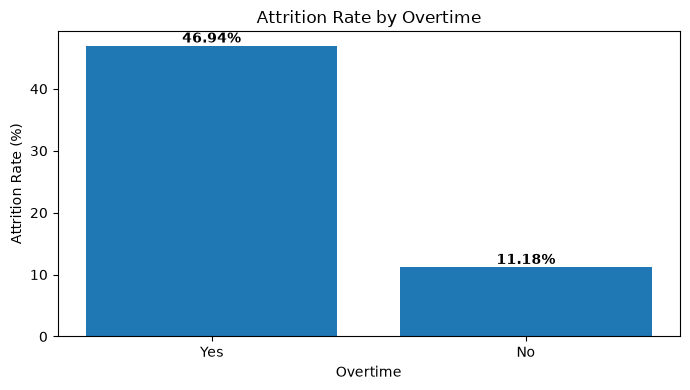

Overtime
Yes    46.94
No     11.18
Name: Attrition_Rate_%, dtype: float64

In [22]:
# 8.1 Overtime vs Attrition

overtime_attrition = (
    df_clean.assign(
        Attrition_Flag=df_clean["Attrition"].map({
            "No": 0,
            "Yes": 1
        })
    )
    .groupby("Overtime")["Attrition_Flag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(7, 4))
bars = plt.bar(
    overtime_attrition.index,
    overtime_attrition.values
)

plt.title("Attrition Rate by Overtime")
plt.xlabel("Overtime")
plt.ylabel("Attrition Rate (%)")

# Show percentage on each bar
for bar, value in zip(bars, overtime_attrition.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

display(
    overtime_attrition.round(2)
    .rename("Attrition_Rate_%")
)


### Interpretation — Attrition Rate by Overtime

The chart shows a strong difference in attrition rates between the two overtime groups. The attrition rate is approximately **11.18% for employees without overtime**, compared with approximately **46.94% for employees with overtime**. In this dataset, employees who work overtime therefore have a much higher observed attrition rate. This is an **association in the dataset**, not proof that overtime alone causes employees to leave.


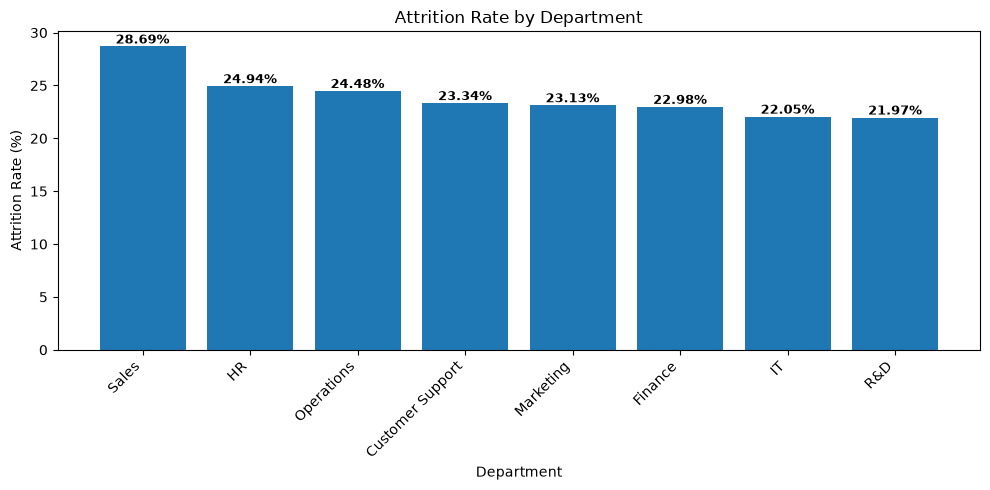

Department
Sales               28.69
HR                  24.94
Operations          24.48
Customer Support    23.34
Marketing           23.13
Finance             22.98
IT                  22.05
R&D                 21.97
Name: Attrition_Rate_%, dtype: float64

In [23]:

# 8.2 Department vs Attrition

department_attrition = (
    df_clean.assign(
        Attrition_Flag=df_clean["Attrition"].map({
            "No": 0,
            "Yes": 1
        })
    )
    .groupby("Department")["Attrition_Flag"]
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
bars = plt.bar(
    department_attrition.index,
    department_attrition.values
)

plt.title("Attrition Rate by Department")
plt.xlabel("Department")
plt.ylabel("Attrition Rate (%)")
plt.xticks(rotation=45, ha="right")

# Show percentage on each bar
for bar, value in zip(bars, department_attrition.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=9,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

display(
    department_attrition.round(2)
    .rename("Attrition_Rate_%")
)



### Interpretation — Attrition Rate by Department

The chart shows that attrition rates vary across departments. **Sales has the highest observed attrition rate (about 28.69%)**, while **R&D has the lowest (about 21.97%)**. The remaining departments fall between these values. This indicates that attrition is not distributed equally across departments and that department is potentially relevant for understanding employee attrition patterns.


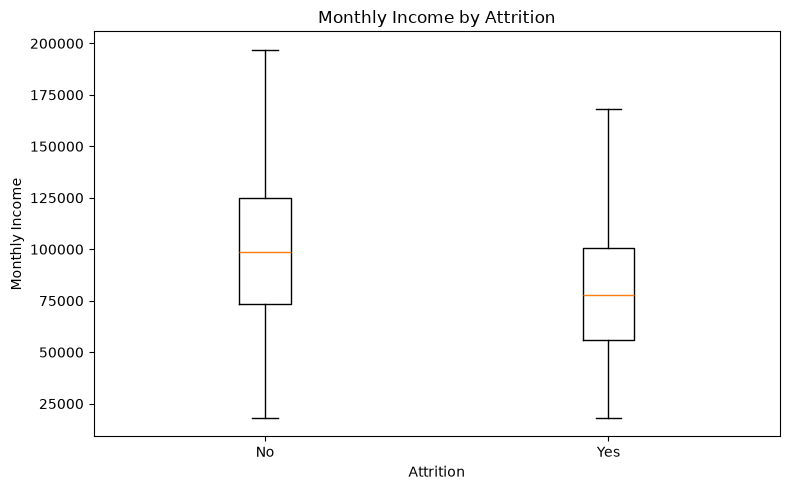

,mean,median,std
Attrition,,,
No,100279.54,98550.0,35974.76
Yes,80466.00,77600.0,30688.06


In [24]:
# 8.3 Monthly income by Attrition

income_no = df_clean.loc[
    df_clean["Attrition"] == "No",
    "Monthly_Income"
]

income_yes = df_clean.loc[
    df_clean["Attrition"] == "Yes",
    "Monthly_Income"
]

plt.figure(figsize=(8, 5))

plt.boxplot(
    [income_no, income_yes],
    tick_labels=["No", "Yes"],
    showfliers=False
)

plt.title("Monthly Income by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Monthly Income")

plt.tight_layout()
plt.show()

display(
    df_clean.groupby("Attrition")["Monthly_Income"]
    .agg(["mean", "median", "std"])
    .round(2)
)

### Interpretation — Monthly Income by Attrition

The boxplot shows that employees with **No Attrition** generally have higher monthly income than employees with **Attrition**. The mean income is approximately **100,280** for employees who stayed and **80,466** for employees who left; the corresponding medians are **98,550** and **77,600**. The distributions also overlap, so income alone does not completely separate the two groups. The chart indicates an observed relationship between lower monthly income and higher attrition in this dataset.


,mean,median,std
Attrition,,,
No,8.55,8.0,5.35
Yes,4.53,4.0,3.97


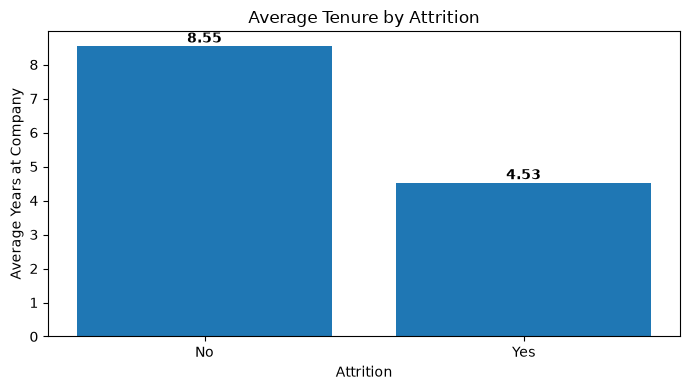

In [25]:

# 8.4 Tenure by Attrition

tenure_by_attrition = (
    df_clean.groupby("Attrition")["Years_at_Company"]
    .agg(["mean", "median", "std"])
    .round(2)
)

display(tenure_by_attrition)

plt.figure(figsize=(7, 4))
bars = plt.bar(
    tenure_by_attrition.index,
    tenure_by_attrition["mean"].values
)

plt.title("Average Tenure by Attrition")
plt.xlabel("Attrition")
plt.ylabel("Average Years at Company")

# Show average years on each bar
for bar, value in zip(
    bars,
    tenure_by_attrition["mean"].values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()



### Interpretation — Average Tenure by Attrition

The chart shows a clear difference in average tenure between the two groups. Employees with **No Attrition** have an average tenure of approximately **8.55 years**, while employees with **Attrition** have an average tenure of approximately **4.53 years**. This indicates that employees who left the company generally had shorter tenure in this dataset.


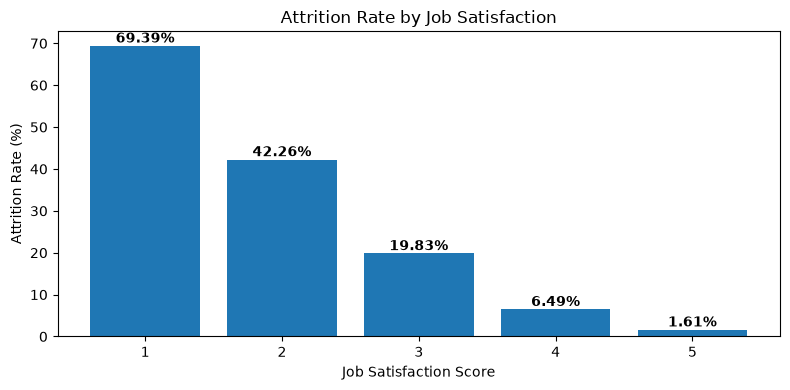

Job_Satisfaction_Display
1    69.39
2    42.26
3    19.83
4     6.49
5     1.61
Name: Attrition_Rate_%, dtype: float64

In [26]:

# 8.5 Job Satisfaction vs Attrition

satisfaction_display = (
    df_clean["Job_Satisfaction"]
    .round()
    .astype(int)
)

satisfaction_attrition = (
    pd.DataFrame({
        "Job_Satisfaction_Display": satisfaction_display,
        "Attrition_Flag": df_clean["Attrition"].map({
            "No": 0,
            "Yes": 1
        })
    })
    .groupby("Job_Satisfaction_Display")["Attrition_Flag"]
    .mean()
    .mul(100)
)

plt.figure(figsize=(8, 4))
bars = plt.bar(
    satisfaction_attrition.index.astype(str),
    satisfaction_attrition.values
)

plt.title("Attrition Rate by Job Satisfaction")
plt.xlabel("Job Satisfaction Score")
plt.ylabel("Attrition Rate (%)")

# Show percentage on each bar
for bar, value in zip(
    bars,
    satisfaction_attrition.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.2f}%",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.tight_layout()
plt.show()

display(
    satisfaction_attrition.round(2)
    .rename("Attrition_Rate_%")
)





### Interpretation — Attrition Rate by Job Satisfaction

The chart shows a strong inverse pattern between job satisfaction and observed attrition. The attrition rate is approximately **69.39% at satisfaction score 1**, **42.26% at score 2**, **19.83% at score 3**, **6.49% at score 4**, and **1.61% at score 5**. Thus, lower job-satisfaction scores are associated with substantially higher attrition rates in this dataset. This is an observed relationship and should not be interpreted as proof of causation.


# CHAPTER 9: EDA — MULTIVARIATE ANALYSIS

## Step 9: Multivariate Analysis

Multivariate analysis studies relationships among several variables simultaneously.

The project uses:

- Correlation heatmap of important numerical variables
- Income vs tenure scatter plot separated by attrition class
- Department + overtime + attrition comparison


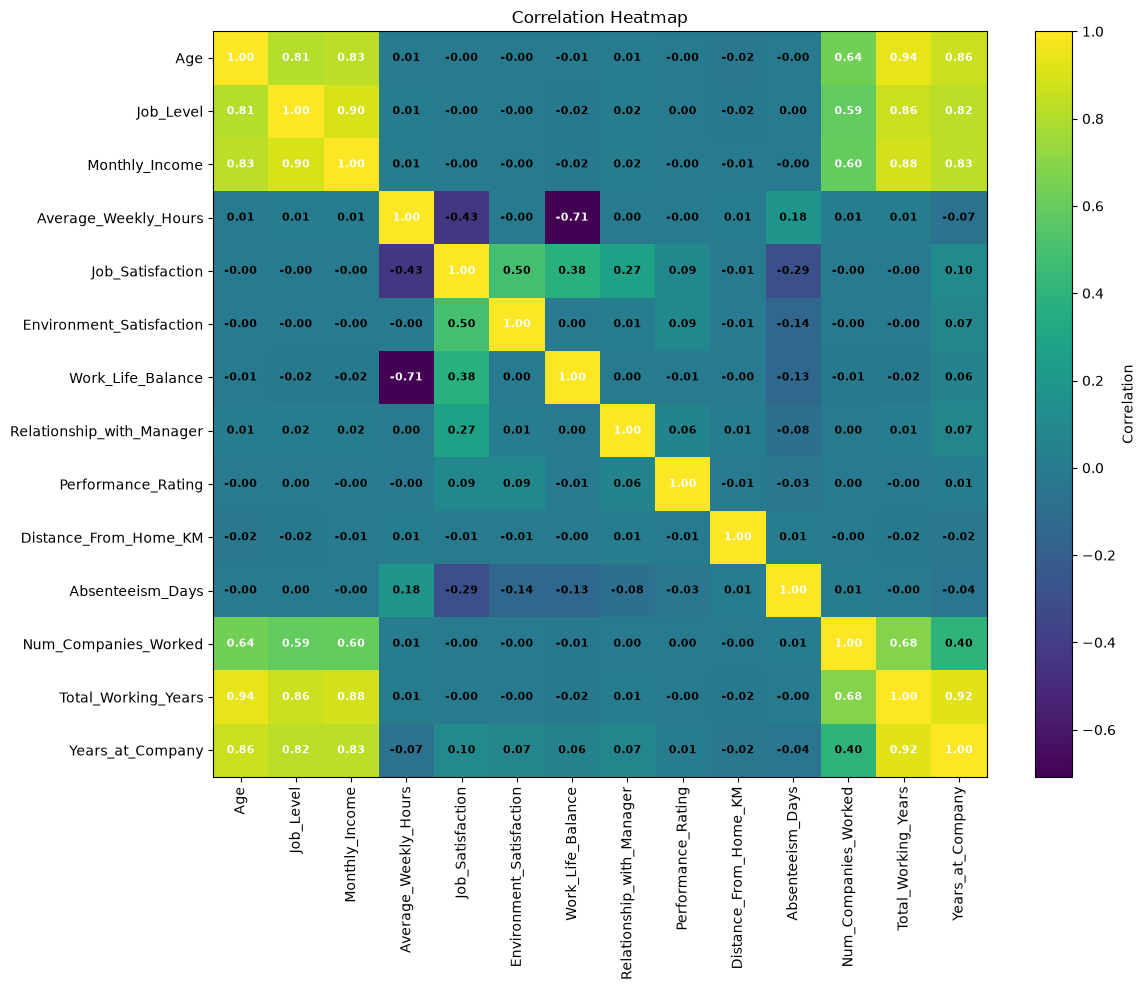

,Age,Job_Level,Monthly_Income,Average_Weekly_Hours,Job_Satisfaction,Environment_Satisfaction,Work_Life_Balance,Relationship_with_Manager,Performance_Rating,Distance_From_Home_KM,Absenteeism_Days,Num_Companies_Worked,Total_Working_Years,Years_at_Company
Age,1.00,0.81,0.83,0.01,-0.00,-0.00,-0.01,0.01,-0.00,-0.02,-0.00,0.64,0.94,0.86
Job_Level,0.81,1.00,0.90,0.01,-0.00,-0.00,-0.02,0.02,0.00,-0.02,0.00,0.59,0.86,0.82
Monthly_Income,0.83,0.90,1.00,0.01,-0.00,-0.00,-0.02,0.02,-0.00,-0.01,-0.00,0.60,0.88,0.83
Average_Weekly_Hours,0.01,0.01,0.01,1.00,-0.43,-0.00,-0.71,0.00,-0.00,0.01,0.18,0.01,0.01,-0.07
Job_Satisfaction,-0.00,-0.00,-0.00,-0.43,1.00,0.50,0.38,0.27,0.09,-0.01,-0.29,-0.00,-0.00,0.10
Environment_Satisfaction,-0.00,-0.00,-0.00,-0.00,0.50,1.00,0.00,0.01,0.09,-0.01,-0.14,-0.00,-0.00,0.07
Work_Life_Balance,-0.01,-0.02,-0.02,-0.71,0.38,0.00,1.00,0.00,-0.01,-0.00,-0.13,-0.01,-0.02,0.06
Relationship_with_Manager,0.01,0.02,0.02,0.00,0.27,0.01,0.00,1.00,0.06,0.01,-0.08,0.00,0.01,0.07
Performance_Rating,-0.00,0.00,-0.00,-0.00,0.09,0.09,-0.01,0.06,1.00,-0.01,-0.03,0.00,-0.00,0.01
Distance_From_Home_KM,-0.02,-0.02,-0.01,0.01,-0.01,-0.01,-0.00,0.01,-0.01,1.00,0.01,-0.00,-0.02,-0.02


In [27]:
# 9.1 Correlation heatmap using Matplotlib
corr_cols = [
    "Age",
    "Job_Level",
    "Monthly_Income",
    "Average_Weekly_Hours",
    "Job_Satisfaction",
    "Environment_Satisfaction",
    "Work_Life_Balance",
    "Relationship_with_Manager",
    "Performance_Rating",
    "Distance_From_Home_KM",
    "Absenteeism_Days",
    "Num_Companies_Worked",
    "Total_Working_Years",
    "Years_at_Company"
]

corr = df_clean[corr_cols].corr()

plt.figure(figsize=(12, 10))
image = plt.imshow(corr, aspect="auto")
plt.colorbar(image, label="Correlation")

plt.xticks(range(len(corr_cols)), corr_cols, rotation=90)
plt.yticks(range(len(corr_cols)), corr_cols)

# 🔹 Correlation values inside each box
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        value = corr.iloc[i, j]
        text_color = "white" if abs(value) >= 0.5 else "black"
        plt.text(
            j, i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold",
            color=text_color
        )

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

display(corr.round(2))

### Interpretation — Correlation Heatmap

The heatmap shows the strength and direction of linear relationships among the selected numerical variables. Values close to **+1** indicate a strong positive relationship, values close to **-1** indicate a strong negative relationship, and values near **0** indicate a weak linear relationship.

For `Years_at_Company`, the strongest positive correlations in this dataset are with **Total_Working_Years (0.92)**, **Age (0.86)**, **Monthly_Income (0.83)** and **Job_Level (0.82)**. Most satisfaction and workplace variables have relatively weak positive correlations with tenure. `Average_Weekly_Hours` has a small negative correlation with tenure (**-0.07**).

The numbers inside the heatmap cells make these relationships directly readable without having to estimate them from the color intensity.


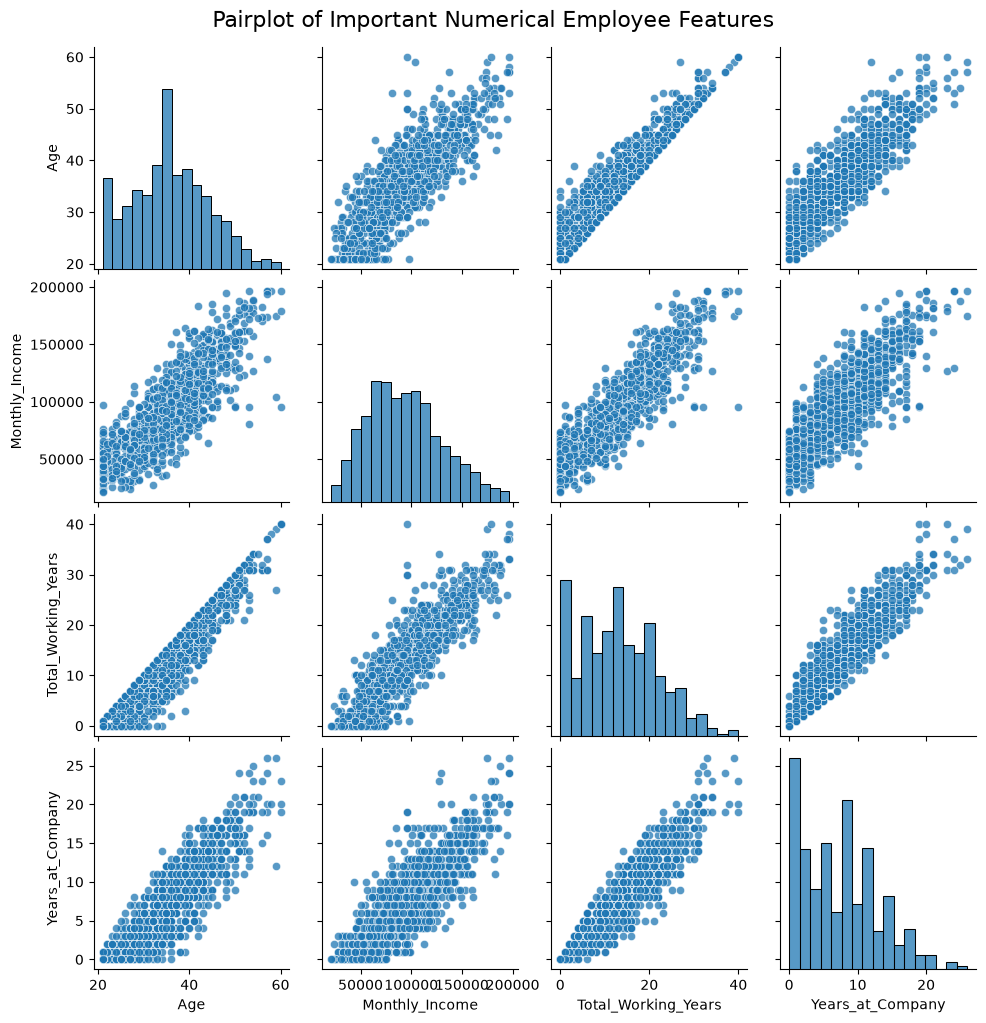

In [64]:
# ---------------------------------------------------------
# Pairplot: Relationship between important numerical features
# ---------------------------------------------------------

import seaborn as sns
import matplotlib.pyplot as plt

# Select 4 important numerical features
pairplot_data = df_clean[
    [
        'Age',
        'Monthly_Income',
        'Total_Working_Years',
        'Years_at_Company'
    ]
].dropna()

# Use a sample for faster plotting
pairplot_sample = pairplot_data.sample(
    n=min(1000, len(pairplot_data)),
    random_state=42
)

# Create pairplot
sns.pairplot(
    pairplot_sample,
    diag_kind='hist',
    height=2.5,
    plot_kws={
        'alpha': 0.75,
        's': 35
    }
)

plt.suptitle(
    "Pairplot of Important Numerical Employee Features",
    y=1.02,
    fontsize=16
)





plt.show()





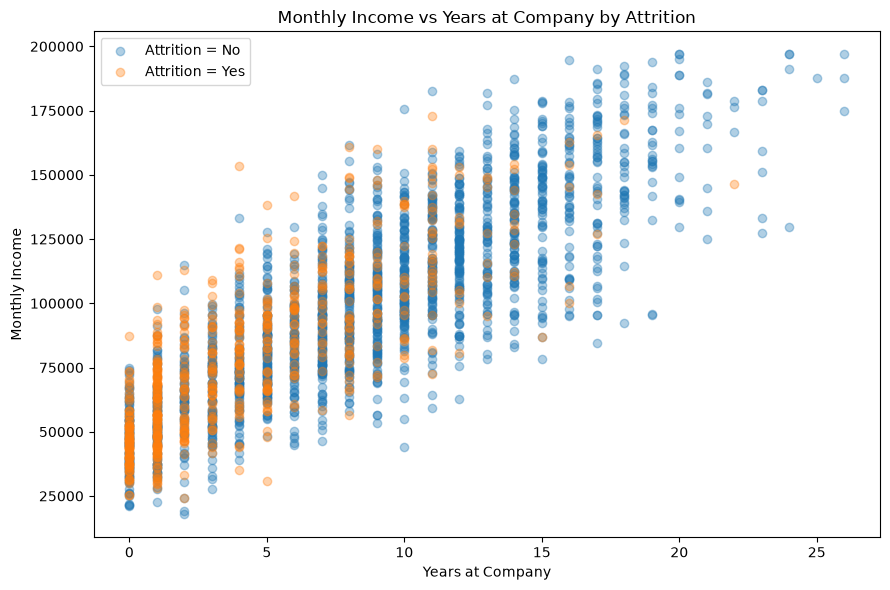

In [29]:
# 9.2 Income vs Tenure colored by Attrition
plot_sample = df_clean.sample(n=2500, random_state=42)

plt.figure(figsize=(9, 6))

no_data = plot_sample[plot_sample["Attrition"] == "No"]
yes_data = plot_sample[plot_sample["Attrition"] == "Yes"]

plt.scatter(
    no_data["Years_at_Company"],
    no_data["Monthly_Income"],
    alpha=0.35,
    label="Attrition = No"
)
plt.scatter(
    yes_data["Years_at_Company"],
    yes_data["Monthly_Income"],
    alpha=0.35,
    label="Attrition = Yes"
)

plt.title("Monthly Income vs Years at Company by Attrition")
plt.xlabel("Years at Company")
plt.ylabel("Monthly Income")
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation — Monthly Income vs Years at Company by Attrition

The scatter plot shows a strong positive relationship between **Years at Company** and **Monthly Income**: employees with longer tenure generally appear at higher income levels. The overall correlation between these two variables is approximately **0.83**, indicating a strong positive linear association.

The points are also separated by attrition status, allowing the two groups to be compared. Employees with attrition are more concentrated toward lower tenure and lower income values, while employees without attrition extend more strongly into the higher-tenure and higher-income region. However, there is overlap between the groups, so income and tenure together do not perfectly distinguish attrition status.


Overtime,No,Yes
Department,,
Customer Support,11.76,46.27
Finance,10.72,46.58
HR,11.55,50.00
IT,10.23,44.06
Marketing,11.18,42.84
Operations,10.94,49.12
R&D,10.10,43.75
Sales,13.50,51.90


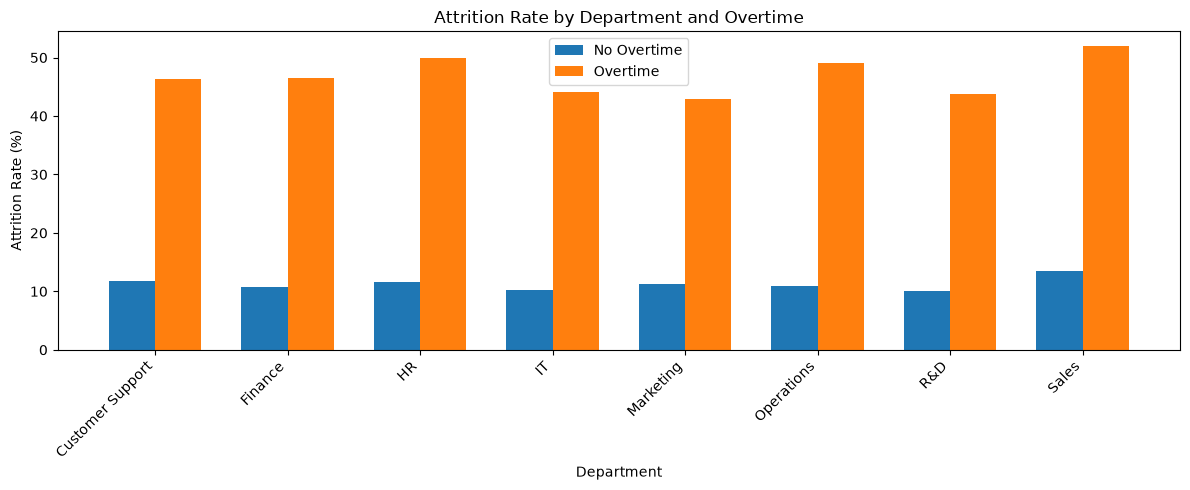

In [30]:
# 9.3 Department + Overtime + Attrition
multi_table = (
    df_clean.assign(Attrition_Flag=df_clean["Attrition"].map({"No": 0, "Yes": 1}))
    .groupby(["Department", "Overtime"])["Attrition_Flag"]
    .mean()
    .mul(100)
    .unstack()
    .fillna(0)
)

display(multi_table.round(2))

x = np.arange(len(multi_table.index))
width = 0.35

plt.figure(figsize=(12, 5))
plt.bar(x - width/2, multi_table.get("No", pd.Series(0, index=multi_table.index)), width, label="No Overtime")
plt.bar(x + width/2, multi_table.get("Yes", pd.Series(0, index=multi_table.index)), width, label="Overtime")
plt.xticks(x, multi_table.index, rotation=45, ha="right")
plt.ylabel("Attrition Rate (%)")
plt.xlabel("Department")
plt.title("Attrition Rate by Department and Overtime")
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation — Attrition Rate by Department and Overtime

The chart combines department and overtime to show how attrition rates change across both factors. In **every department shown, the overtime group has a much higher observed attrition rate than the no-overtime group**. For example, Sales is approximately **51.90% with overtime versus 13.50% without overtime**, while HR is approximately **50.00% versus 11.55%**.

This indicates that the overtime–attrition association is present across departments rather than being limited to one department. The chart also shows that the size of this difference varies somewhat by department. These are dataset-level associations, not causal conclusions.


# CHAPTER 10: REGRESSION ANALYSIS

## Step 10: Tenure Duration Regression Model

### Target

`Years_at_Company`

### Leakage Prevention

The following columns are removed from the regression input:

- `Employee_ID` — identifier only
- `Attrition` — separate classification target
- `Years_in_Current_Role`
- `Years_Since_Last_Promotion`
- `Years_with_Current_Manager`

The last three are strongly derived from company tenure, so excluding them makes the regression task more academically valid and reduces target-proxy leakage.


In [31]:
# Prepare regression data
regression_drop_columns = [
    "Employee_ID",
    "Years_at_Company",
    "Attrition",
    "Years_in_Current_Role",
    "Years_Since_Last_Promotion",
    "Years_with_Current_Manager"
]

X_reg = df_clean.drop(columns=regression_drop_columns)
y_reg = df_clean["Years_at_Company"]

reg_numeric = X_reg.select_dtypes(exclude="object").columns.tolist()
reg_categorical = X_reg.select_dtypes(include="object").columns.tolist()

print("Regression features:", X_reg.shape[1])
print("Numerical features:", len(reg_numeric))
print("Categorical features:", len(reg_categorical))


Regression features: 24
Numerical features: 15
Categorical features: 9


In [32]:
# 80/20 train-test split
X_reg_train, X_reg_test, y_reg_train, y_reg_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_reg_train))
print("Testing rows :", len(X_reg_test))


Training rows: 16000
Testing rows : 4000


In [33]:
# Preprocessing for Linear Regression
reg_preprocessor_linear = ColumnTransformer([
    ("num", StandardScaler(), reg_numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), reg_categorical)
])

linear_regression_model = Pipeline([
    ("preprocess", reg_preprocessor_linear),
    ("model", LinearRegression())
])

linear_regression_model.fit(X_reg_train, y_reg_train)
linear_reg_pred = linear_regression_model.predict(X_reg_test)

print("Linear Regression trained successfully.")


Linear Regression trained successfully.


In [34]:
# Random Forest Regressor for comparison
reg_preprocessor_rf = ColumnTransformer([
    ("num", "passthrough", reg_numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), reg_categorical)
])

random_forest_regressor = Pipeline([
    ("preprocess", reg_preprocessor_rf),
    ("model", RandomForestRegressor(
        n_estimators=180,
        max_depth=14,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_regressor.fit(X_reg_train, y_reg_train)
rf_reg_pred = random_forest_regressor.predict(X_reg_test)

print("Random Forest Regressor trained successfully.")


Random Forest Regressor trained successfully.


# CHAPTER 11: REGRESSION MODEL EVALUATION

## Step 11: Evaluating the Tenure Models

Metrics:

- **MAE** — average absolute prediction error
- **MSE** — average squared prediction error
- **RMSE** — error in the original tenure unit (years)
- **R²** — proportion of variance explained by the model


In [35]:
# Regression evaluation function
def regression_metrics(y_true, y_pred, model_name):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "R2": r2_score(y_true, y_pred)
    }

regression_results = pd.DataFrame([
    regression_metrics(y_reg_test, linear_reg_pred, "Linear Regression"),
    regression_metrics(y_reg_test, rf_reg_pred, "Random Forest Regressor")
]).set_index("Model")

display(regression_results.round(4))


,MAE,MSE,RMSE,R2
Model,,,,
Linear Regression,0.8466,1.1433,1.0693,0.9599
Random Forest Regressor,0.8440,1.2508,1.1184,0.9562


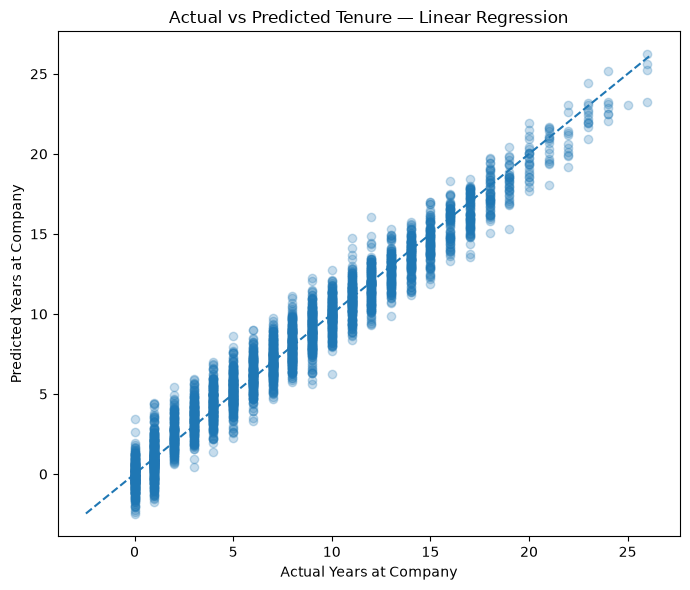

In [36]:
# Actual vs predicted tenure for Linear Regression
plt.figure(figsize=(7, 6))
plt.scatter(y_reg_test, linear_reg_pred, alpha=0.25)
minimum = min(y_reg_test.min(), linear_reg_pred.min())
maximum = max(y_reg_test.max(), linear_reg_pred.max())
plt.plot([minimum, maximum], [minimum, maximum], linestyle="--")
plt.title("Actual vs Predicted Tenure — Linear Regression")
plt.xlabel("Actual Years at Company")
plt.ylabel("Predicted Years at Company")
plt.tight_layout()
plt.show()


### Interpretation — Actual vs Predicted Tenure

The diagonal dashed line represents perfect prediction, where predicted tenure equals actual tenure. Most points are concentrated close to this line, indicating that the Linear Regression model's predicted tenure values are generally close to the actual tenure values.

The model's test **R² is approximately 0.960**, and the correlation between actual and predicted tenure is approximately **0.980**. About **65.6% of test predictions are within 1 year** of the actual tenure, and about **93.8% are within 2 years**. Therefore, the plot indicates a strong agreement between actual and predicted tenure values, while some prediction error remains.


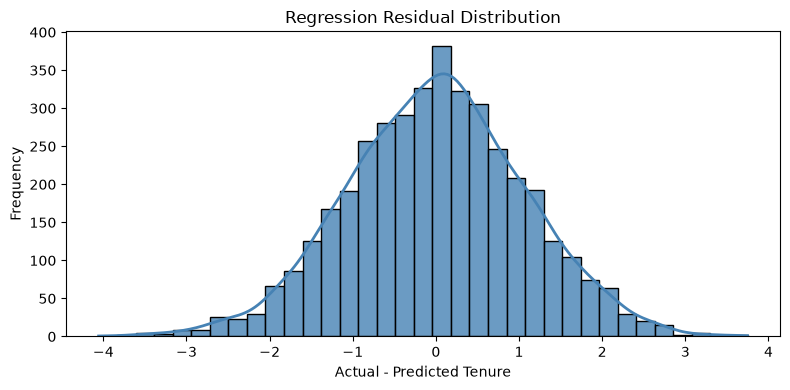

Mean residual: 0.0022


In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

# Residual distribution with KDE
linear_residuals = y_reg_test - linear_reg_pred

plt.figure(figsize=(8, 4))

sns.histplot(
    x=linear_residuals,
    bins=35,
    kde=True,
    edgecolor="black",
    alpha=0.8,
    color="steelblue",
    line_kws={"color": "red", "linewidth": 2}
)

plt.title("Regression Residual Distribution")
plt.xlabel("Actual - Predicted Tenure")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print("Mean residual:", round(linear_residuals.mean(), 4))


### Interpretation — Regression Residual Distribution

A residual is calculated as **Actual − Predicted**. Therefore, values near zero represent small prediction errors. The residual distribution is centered very close to zero, with a mean residual of approximately **0.002 years**.

The residual standard deviation is about **1.07 years**, and the distribution is approximately symmetric (skewness about **-0.05**). This indicates that the Linear Regression model does not show a substantial overall tendency to systematically overpredict or underpredict tenure. Most residuals are relatively close to zero, although some larger errors are present.


# CHAPTER 12: CLASSIFICATION MODEL

## Step 12: Employee Attrition Classification

### Target

`Attrition`

Encoding:

- `No` → 0
- `Yes` → 1

Two models are compared:

1. Logistic Regression
2. Random Forest Classifier

A stratified 80/20 split is used so that the attrition ratio remains similar in training and testing data.


In [38]:
# Prepare classification data
X_cls = df_clean.drop(columns=["Employee_ID", "Attrition"])
y_cls = df_clean["Attrition"].map({"No": 0, "Yes": 1})

cls_numeric = X_cls.select_dtypes(exclude="object").columns.tolist()
cls_categorical = X_cls.select_dtypes(include="object").columns.tolist()

X_cls_train, X_cls_test, y_cls_train, y_cls_test = train_test_split(
    X_cls,
    y_cls,
    test_size=0.20,
    random_state=42,
    stratify=y_cls
)

print("Training rows:", len(X_cls_train))
print("Testing rows :", len(X_cls_test))
print("\nTraining class distribution:")
display((y_cls_train.value_counts(normalize=True) * 100).round(2).rename("Percentage"))


Training rows: 16000
Testing rows : 4000

Training class distribution:


Attrition
0    76.0
1    24.0
Name: Percentage, dtype: float64

In [39]:
# Logistic Regression pipeline
cls_preprocessor_logistic = ColumnTransformer([
    ("num", StandardScaler(), cls_numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cls_categorical)
])

logistic_model = Pipeline([
    ("preprocess", cls_preprocessor_logistic),
    ("model", LogisticRegression(max_iter=2000, random_state=42))
])

logistic_model.fit(X_cls_train, y_cls_train)

logistic_pred = logistic_model.predict(X_cls_test)
logistic_prob = logistic_model.predict_proba(X_cls_test)[:, 1]

print("Logistic Regression trained successfully.")


Logistic Regression trained successfully.


In [40]:
# Random Forest Classification pipeline
cls_preprocessor_rf = ColumnTransformer([
    ("num", "passthrough", cls_numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cls_categorical)
])

random_forest_classifier = Pipeline([
    ("preprocess", cls_preprocessor_rf),
    ("model", RandomForestClassifier(
        n_estimators=220,
        max_depth=16,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_classifier.fit(X_cls_train, y_cls_train)

rf_cls_pred = random_forest_classifier.predict(X_cls_test)
rf_cls_prob = random_forest_classifier.predict_proba(X_cls_test)[:, 1]

print("Random Forest Classifier trained successfully.")


Random Forest Classifier trained successfully.


# CHAPTER 13: CLASSIFICATION MODEL EVALUATION

## Step 13: Evaluating Attrition Prediction

Metrics:

- Accuracy
- Precision
- Recall
- F1 Score
- ROC-AUC
- Confusion Matrix
- Classification Report

Accuracy is not used alone because attrition classes are not perfectly balanced.


In [41]:
# Classification evaluation function
def classification_metrics(y_true, y_pred, y_prob, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "ROC_AUC": roc_auc_score(y_true, y_prob)
    }

classification_results = pd.DataFrame([
    classification_metrics(
        y_cls_test, logistic_pred, logistic_prob, "Logistic Regression"
    ),
    classification_metrics(
        y_cls_test, rf_cls_pred, rf_cls_prob, "Random Forest Classifier"
    )
]).set_index("Model")

display(classification_results.round(4))


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic Regression,0.9442,0.8875,0.8792,0.8833,0.9856
Random Forest Classifier,0.9218,0.8989,0.7594,0.8233,0.9742


Confusion Matrix — Logistic Regression
[[2933  107]
 [ 116  844]]


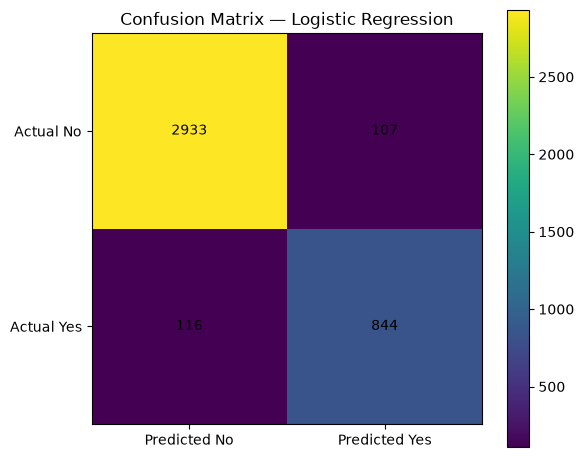

In [42]:
# Confusion matrix for Logistic Regression
cm = confusion_matrix(y_cls_test, logistic_pred)

print("Confusion Matrix — Logistic Regression")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm)
plt.colorbar()
plt.xticks([0, 1], ["Predicted No", "Predicted Yes"])
plt.yticks([0, 1], ["Actual No", "Actual Yes"])

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()


### Interpretation — Confusion Matrix for Logistic Regression

The confusion matrix shows how the Logistic Regression model classified the 4,000 test employees:

- **2,933** employees were correctly predicted as **No Attrition**.
- **844** employees were correctly predicted as **Attrition**.
- **107** employees who did not leave were incorrectly predicted as leaving (**False Positives**).
- **116** employees who left were incorrectly predicted as staying (**False Negatives**).

Thus, the model correctly identifies most observations in both classes. For the Attrition class specifically, the recall is approximately **87.92%**, meaning the model identifies most of the employees who actually left.


In [43]:
# Classification report
print("Classification Report — Logistic Regression")
print(
    classification_report(
        y_cls_test,
        logistic_pred,
        target_names=["No Attrition", "Attrition"]
    )
)


Classification Report — Logistic Regression
              precision    recall  f1-score   support

No Attrition       0.96      0.96      0.96      3040
   Attrition       0.89      0.88      0.88       960

    accuracy                           0.94      4000
   macro avg       0.92      0.92      0.92      4000
weighted avg       0.94      0.94      0.94      4000



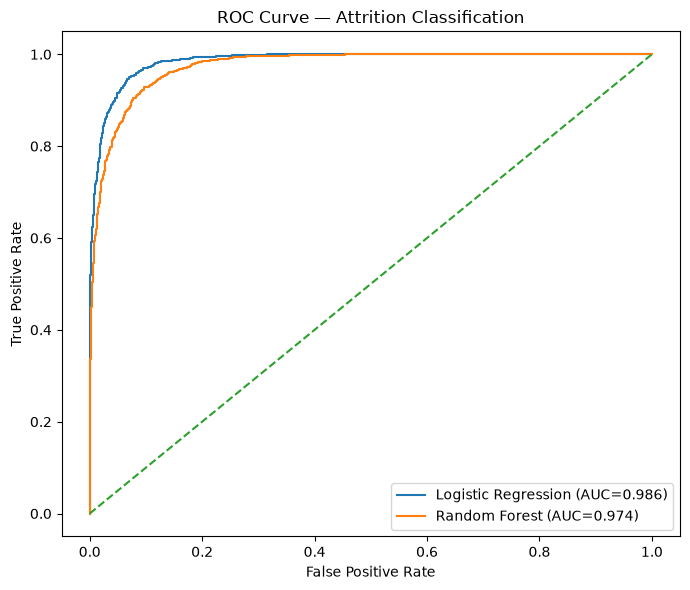

In [44]:
# ROC curves
log_fpr, log_tpr, _ = roc_curve(y_cls_test, logistic_prob)
rf_fpr, rf_tpr, _ = roc_curve(y_cls_test, rf_cls_prob)

plt.figure(figsize=(7, 6))
plt.plot(
    log_fpr,
    log_tpr,
    label=f"Logistic Regression (AUC={roc_auc_score(y_cls_test, logistic_prob):.3f})"
)
plt.plot(
    rf_fpr,
    rf_tpr,
    label=f"Random Forest (AUC={roc_auc_score(y_cls_test, rf_cls_prob):.3f})"
)
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve — Attrition Classification")
plt.legend()
plt.tight_layout()
plt.show()


### Interpretation — ROC Curve for Attrition Classification

The ROC curve compares the **True Positive Rate** with the **False Positive Rate** at different classification thresholds. A curve closer to the upper-left region indicates better separation between the two classes, while the diagonal line represents random classification.

The Logistic Regression model has an **ROC-AUC of approximately 0.986**, while the Random Forest Classifier has an **ROC-AUC of approximately 0.974**. Both values indicate strong class-separation performance on this test set. The ROC curve therefore shows that both models can distinguish attrition from non-attrition substantially better than random classification.


# CHAPTER 14: UNDERFITTING AND OVERFITTING

## Step 14: Training vs Testing Performance

General interpretation:

- **Underfitting:** training and testing performance are both weak.
- **Overfitting:** training performance is much stronger than testing performance.
- **Good generalization:** training and testing performance are both strong and reasonably close.

We compare both regression and classification models.


In [45]:
# Regression train/test R²
linear_train_pred = linear_regression_model.predict(X_reg_train)
rf_reg_train_pred = random_forest_regressor.predict(X_reg_train)

reg_fit_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest Regressor"],
    "Train_R2": [
        r2_score(y_reg_train, linear_train_pred),
        r2_score(y_reg_train, rf_reg_train_pred)
    ],
    "Test_R2": [
        r2_score(y_reg_test, linear_reg_pred),
        r2_score(y_reg_test, rf_reg_pred)
    ]
})

reg_fit_comparison["Gap"] = (
    reg_fit_comparison["Train_R2"] - reg_fit_comparison["Test_R2"]
).abs()

display(reg_fit_comparison.round(4))


,Model,Train_R2,Test_R2,Gap
0,Linear Regression,0.9593,0.9599,0.0006
1,Random Forest Regressor,0.9889,0.9562,0.0327


In [46]:
# Classification train/test accuracy
logistic_train_pred = logistic_model.predict(X_cls_train)
rf_cls_train_pred = random_forest_classifier.predict(X_cls_train)

cls_fit_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest Classifier"],
    "Train_Accuracy": [
        accuracy_score(y_cls_train, logistic_train_pred),
        accuracy_score(y_cls_train, rf_cls_train_pred)
    ],
    "Test_Accuracy": [
        accuracy_score(y_cls_test, logistic_pred),
        accuracy_score(y_cls_test, rf_cls_pred)
    ]
})

cls_fit_comparison["Gap"] = (
    cls_fit_comparison["Train_Accuracy"] -
    cls_fit_comparison["Test_Accuracy"]
).abs()

display(cls_fit_comparison.round(4))


,Model,Train_Accuracy,Test_Accuracy,Gap
0,Logistic Regression,0.9457,0.9442,0.0014
1,Random Forest Classifier,0.9938,0.9218,0.0721


In [47]:
# Simple fit interpretation
def fit_interpretation(train_score, test_score, strong_threshold):
    gap = abs(train_score - test_score)

    if train_score < strong_threshold and test_score < strong_threshold:
        return "Possible underfitting"
    elif gap > 0.08 and train_score > test_score:
        return "Possible overfitting"
    elif gap <= 0.05:
        return "Good generalization"
    else:
        return "Moderate train-test gap; inspect further"

print("REGRESSION FIT ANALYSIS")
for _, row in reg_fit_comparison.iterrows():
    print(
        row["Model"], "->",
        fit_interpretation(row["Train_R2"], row["Test_R2"], 0.80)
    )

print("\nCLASSIFICATION FIT ANALYSIS")
for _, row in cls_fit_comparison.iterrows():
    print(
        row["Model"], "->",
        fit_interpretation(
            row["Train_Accuracy"],
            row["Test_Accuracy"],
            0.85
        )
    )


REGRESSION FIT ANALYSIS
Linear Regression -> Good generalization
Random Forest Regressor -> Good generalization

CLASSIFICATION FIT ANALYSIS
Logistic Regression -> Good generalization
Random Forest Classifier -> Moderate train-test gap; inspect further


# CHAPTER 15: CONCLUSION

## Step 15: Final Conclusion

This project demonstrates a complete employee analytics workflow using a 20,000-row synthetic HR dataset.

### Regression

The regression analysis predicts `Years_at_Company`. Leakage-prone tenure-derived variables are excluded from the regression inputs. Linear Regression and Random Forest Regression are compared using MAE, MSE, RMSE, and R².

### Classification

The classification analysis predicts `Attrition`. Logistic Regression and Random Forest are evaluated using Accuracy, Precision, Recall, F1 Score, Confusion Matrix, and ROC-AUC.

### Analytical Themes

The EDA investigates relationships involving:

- Overtime
- Job satisfaction
- Work-life balance
- Manager relationship
- Salary
- Weekly working hours
- Absenteeism
- Commute distance
- Promotion history
- Department
- Career experience
- Company tenure




In [48]:
# Final project summary using actual calculated metrics
best_reg_model = regression_results["R2"].idxmax()
best_cls_model = classification_results["Accuracy"].idxmax()

best_reg_r2 = regression_results.loc[best_reg_model, "R2"]
best_reg_rmse = regression_results.loc[best_reg_model, "RMSE"]

best_cls_accuracy = classification_results.loc[best_cls_model, "Accuracy"]
best_cls_f1 = classification_results.loc[best_cls_model, "F1"]
best_cls_auc = classification_results.loc[best_cls_model, "ROC_AUC"]

print("=" * 70)
print("FINAL PROJECT SUMMARY")
print("=" * 70)

print(f"Dataset Rows          : {len(df_clean):,}")
print(f"Dataset Columns       : {df_clean.shape[1]}")

print("\nBEST REGRESSION MODEL")
print(f"Model                 : {best_reg_model}")
print(f"R² Score              : {best_reg_r2:.4f}")
print(f"RMSE                   : {best_reg_rmse:.4f} years")

print("\nBEST CLASSIFICATION MODEL")
print(f"Model                 : {best_cls_model}")
print(f"Accuracy              : {best_cls_accuracy:.4f} ({best_cls_accuracy*100:.2f}%)")
print(f"F1 Score              : {best_cls_f1:.4f}")
print(f"ROC-AUC               : {best_cls_auc:.4f}")

print("\nTARGET CHECK")
print("Regression R² > 0.80 :", best_reg_r2 > 0.80)
print("Accuracy > 90%       :", best_cls_accuracy > 0.90)

print("\nConclusion:")
print(
    "The dataset supports strong regression and classification "
    "performance while still allowing meaningful cleaning, EDA, and model "
    "evaluation steps."
)


FINAL PROJECT SUMMARY
Dataset Rows          : 20,000
Dataset Columns       : 30

BEST REGRESSION MODEL
Model                 : Linear Regression
R² Score              : 0.9599
RMSE                   : 1.0693 years

BEST CLASSIFICATION MODEL
Model                 : Logistic Regression
Accuracy              : 0.9443 (94.42%)
F1 Score              : 0.8833
ROC-AUC               : 0.9856

TARGET CHECK
Regression R² > 0.80 : True
Accuracy > 90%       : True

Conclusion:
The dataset supports strong regression and classification performance while still allowing meaningful cleaning, EDA, and model evaluation steps.
